# Lab 2 – Predicting Diabetes Progression

**Objective:** build a model that best predicts *disease progression one year after baseline*,
to be used as a screening tool that helps physicians identify patients at risk.

**Models:** univariate polynomial regression (BMI), multivariate polynomial regression,
decision trees, k-Nearest Neighbours and logistic regression.

**Metrics:** R², Mean Absolute Error (MAE), Mean Absolute Percentage Error (MAPE) on a
75 % / 10 % / 15 % train / validation / test split.

# Part 1 – Data
## 1. Get the data

`load_diabetes` options used:
- `as_frame=True` – returns a pandas DataFrame with named columns.
- `scaled=False` – keeps the **original units** (e.g. BMI in kg/m², age in years) so the
  BMI equation and predictions in Part 2 are clinically interpretable. The default
  (`scaled=True`) mean-centres each feature and divides by `std * sqrt(n_samples)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
diabetes = datasets.load_diabetes(as_frame=True, scaled=False)
print(diabetes.DESCR[:1500])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

The six blood-serum columns are named `s1`–`s6`. The dataset description tells us what they
measure, so we rename them to make the rest of the report easier to read.

In [3]:
column_names = {
    "s1": "tc",   # total serum cholesterol
    "s2": "ldl",  # low-density lipoproteins
    "s3": "hdl",  # high-density lipoproteins
    "s4": "tch",  # total cholesterol / HDL
    "s5": "ltg",  # log of serum triglycerides level
    "s6": "glu",  # blood sugar level
}
df = diabetes.frame.rename(columns=column_names)
df.head()

,age,sex,bmi,bp,tc,ldl,hdl,tch,ltg,glu,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.860,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.892,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.673,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.890,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.290,80.0,135.0


In [4]:
df.shape

(442, 11)

## 2. Frame the problem

**Target:** `target` – a quantitative measure of *disease progression one year after baseline*
(higher = worse progression). **Inputs:** 10 baseline measurements (age, sex, BMI, average
blood pressure and six blood-serum measurements) for 442 patients.

**Task type:** supervised learning, offline/batch (small, static dataset).
- As stated, it is a **regression** problem – we predict a continuous score
  (polynomial regression, regression trees, kNN regression).
- Because the end use is *screening* (flag patients at risk), it can also be framed as
  **binary classification**: "high progression" vs "low progression". This is how logistic
  regression is used in Part 3.

**Talking points from the workshops**
- *Performance metrics (classification):* in screening, a **false negative** (an at-risk
  patient who is not flagged) is more costly than a false positive (an extra follow-up test),
  so **recall / sensitivity** matters more than raw accuracy. A confusion matrix shows these
  error types separately, and the decision threshold can be lowered to trade precision for recall.
- *k-Nearest Neighbours:* predictions are the average (or vote) of the *k* most similar
  patients. It is distance-based, so features must be **scaled**, and it degrades as the number
  of features grows (curse of dimensionality). Small *k* → low bias / high variance; large *k*
  → smoother, higher bias.
- *Logistic regression:* models the **probability** of the positive class through the sigmoid
  of a linear combination of features. Probabilities are useful for screening because the
  physician can choose the risk threshold, and coefficients are interpretable (log-odds).

**Regression metrics used here**
- **R²** – share of the target's variance explained by the model (1 = perfect, 0 = no better
  than predicting the mean, can be negative).
- **MAE** – average absolute error, in the same units as the target.
- **MAPE** – average absolute error relative to the true value (scale-free, %); sensitive to
  small true values.

**Baseline:** a model that always predicts the training mean (this is exactly the degree-0
polynomial in Part 2). Any useful model must beat it.

> 📝 *Explanation to expand:* clinical context / why progression prediction matters.

## 3. Exploratory Data Analysis
### 3.1 Structure and descriptive statistics

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   tc      442 non-null    float64
 5   ldl     442 non-null    float64
 6   hdl     442 non-null    float64
 7   tch     442 non-null    float64
 8   ltg     442 non-null    float64
 9   glu     442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.518,13.109,19.000,38.250,50.00,59.000,79.000
sex,442.0,1.468,0.500,1.000,1.000,1.00,2.000,2.000
bmi,442.0,26.376,4.418,18.000,23.200,25.70,29.275,42.200
bp,442.0,94.647,13.831,62.000,84.000,93.00,105.000,133.000
tc,442.0,189.140,34.608,97.000,164.250,186.00,209.750,301.000
ldl,442.0,115.439,30.413,41.600,96.050,113.00,134.500,242.400
hdl,442.0,49.788,12.934,22.000,40.250,48.00,57.750,99.000
tch,442.0,4.070,1.290,2.000,3.000,4.00,5.000,9.090
ltg,442.0,4.641,0.522,3.258,4.277,4.62,4.997,6.107
glu,442.0,91.260,11.496,58.000,83.250,91.00,98.000,124.000


In [7]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nSex counts:\n", df["sex"].value_counts())
print("\nSkewness:\n", df.skew().round(2))

Missing values: 0
Duplicate rows: 0

Sex counts:
 sex
1.0    235
2.0    207
Name: count, dtype: int64

Skewness:
 age      -0.23
sex       0.13
bmi       0.60
bp        0.29
tc        0.38
ldl       0.44
hdl       0.80
tch       0.74
ltg       0.29
glu       0.21
target    0.44
dtype: float64


### 3.2 Distributions (histograms)

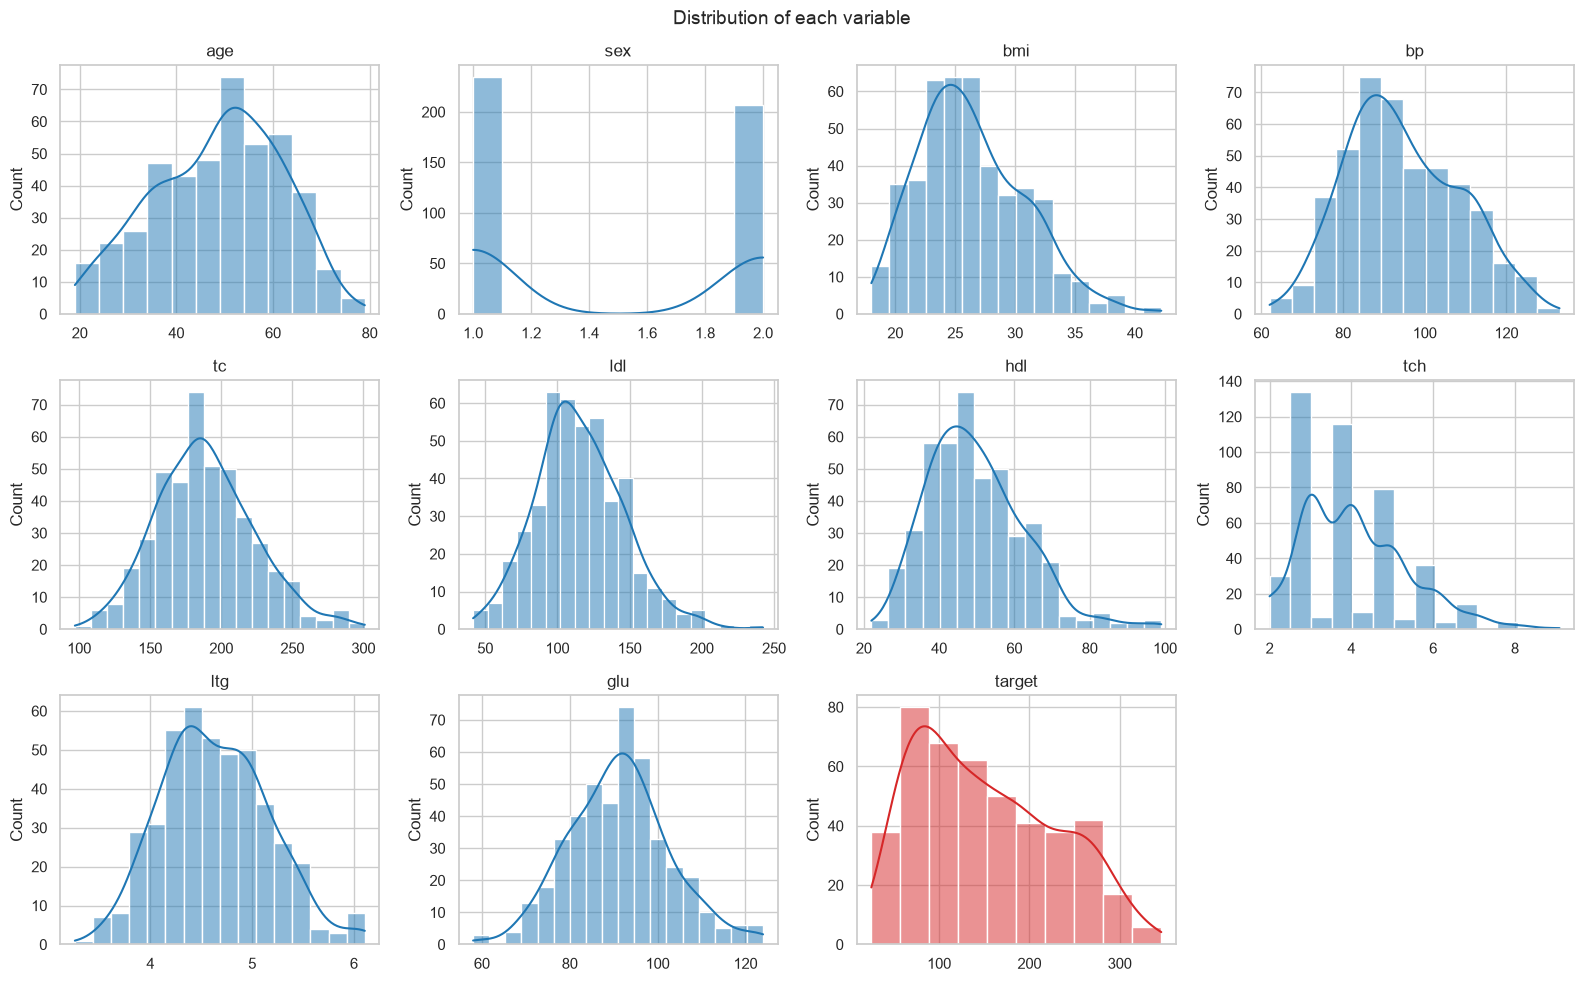

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color="tab:red" if col == "target" else "tab:blue")
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Distribution of each variable", fontsize=14)
fig.tight_layout()
plt.show()

### 3.3 Outliers (box plots, IQR rule)

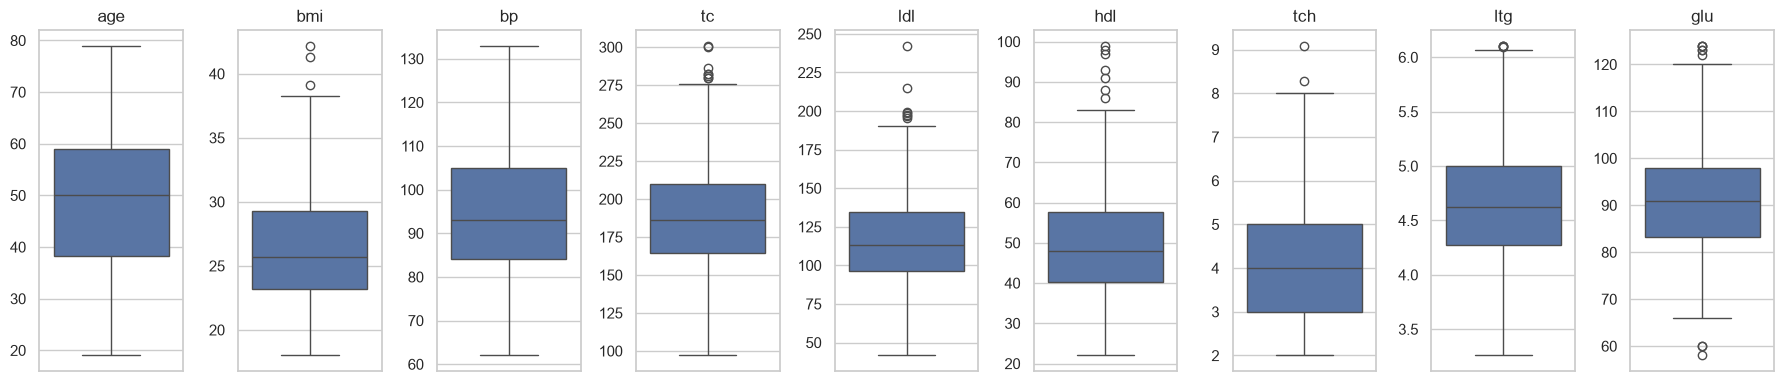

,age,bmi,bp,tc,ldl,hdl,tch,ltg,glu
IQR outliers,0,3,0,8,7,7,2,4,9


In [9]:
features = df.columns.drop(["target", "sex"])
fig, axes = plt.subplots(1, len(features), figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
outliers = ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).sum()
outliers.rename("IQR outliers").to_frame().T

### 3.4 Each feature vs. the target (scatter plots)

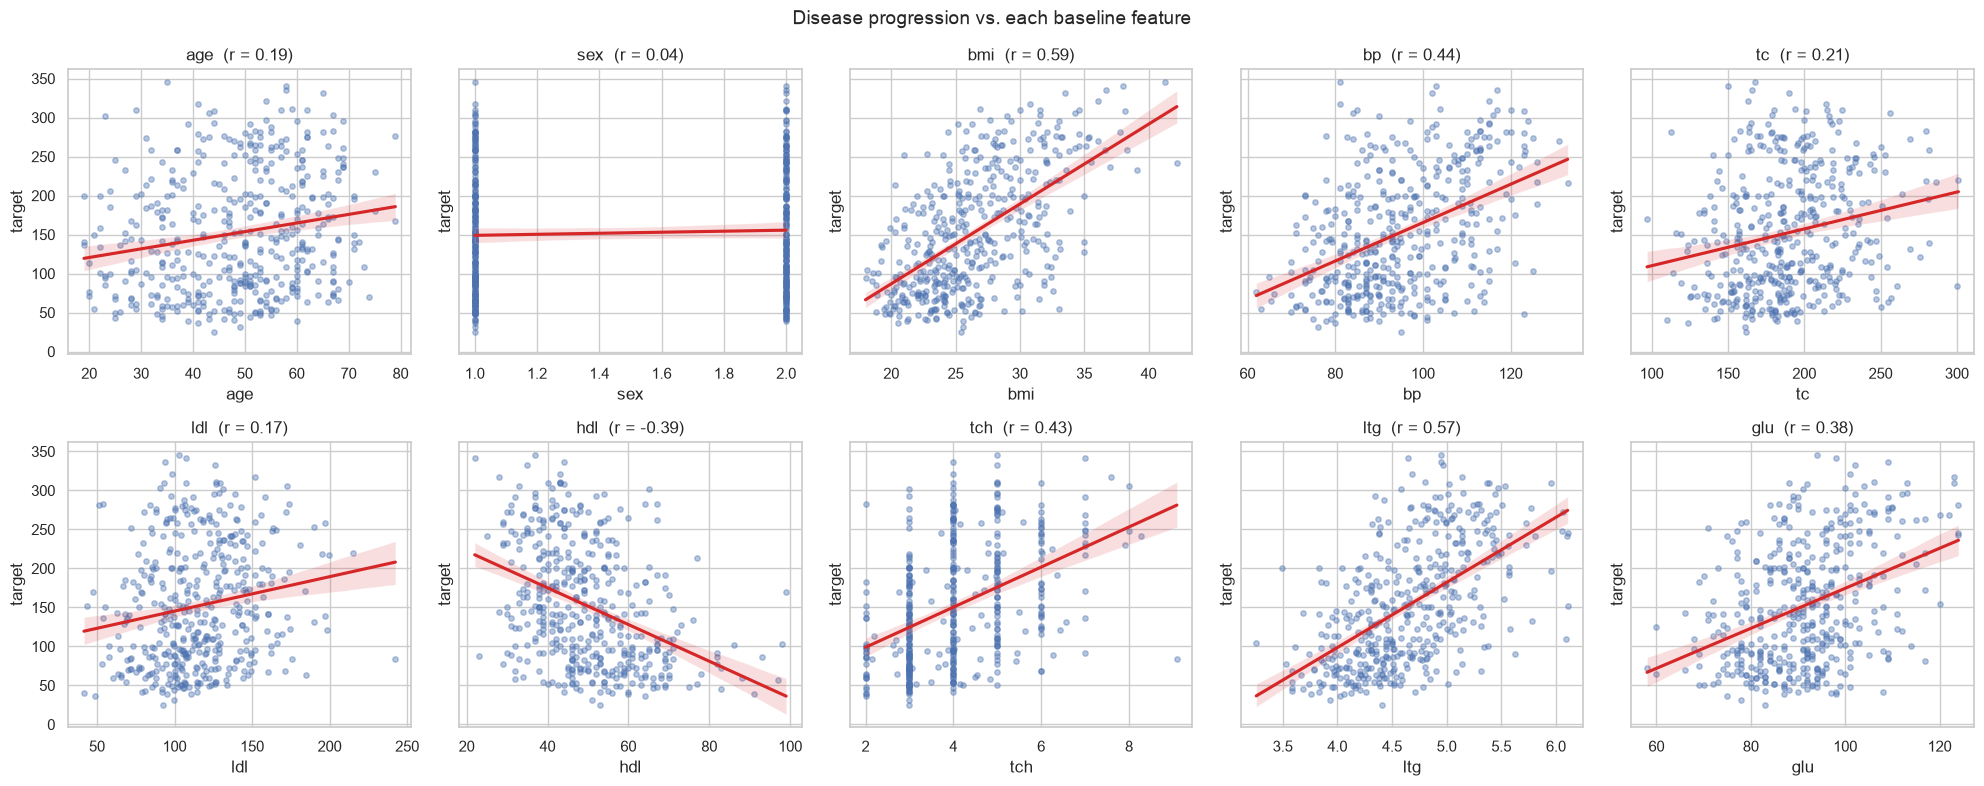

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=True)
for ax, col in zip(axes.flat, df.columns.drop("target")):
    sns.regplot(data=df, x=col, y="target", ax=ax, scatter_kws={"alpha": 0.4, "s": 15},
                line_kws={"color": "tab:red"})
    ax.set_title(f"{col}  (r = {df[col].corr(df['target']):.2f})")
fig.suptitle("Disease progression vs. each baseline feature", fontsize=14)
fig.tight_layout()
plt.show()

### 3.5 Correlation matrix

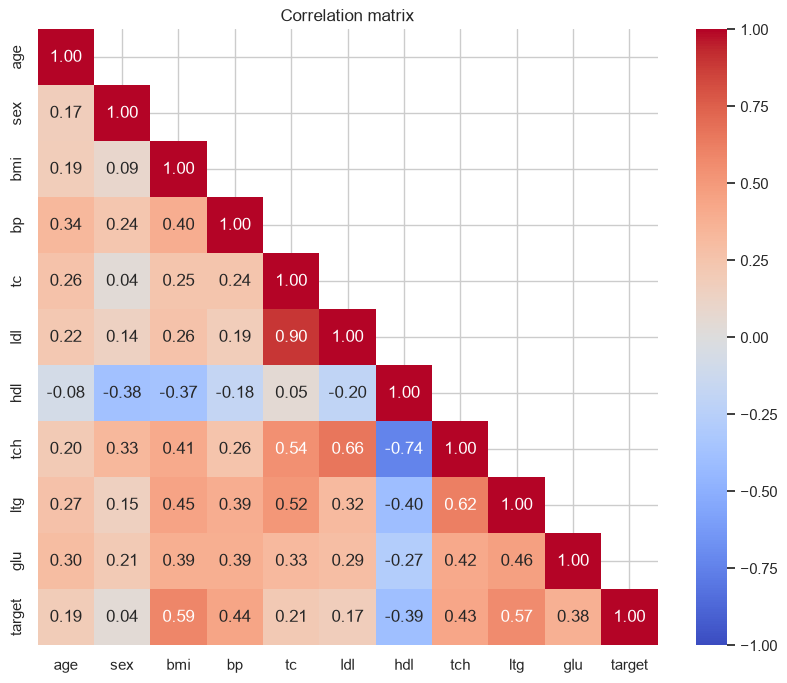

,corr with target
bmi,0.586
ltg,0.566
bp,0.441
tch,0.430
hdl,-0.395
glu,0.382
tc,0.212
age,0.188
ldl,0.174
sex,0.043


In [11]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
plt.title("Correlation matrix")
plt.show()

corr["target"].drop("target").sort_values(key=abs, ascending=False).to_frame("corr with target")

### 3.6 EDA insights

- **Clean, small dataset:** 442 patients, 10 numeric features, no missing values and no duplicates.
- **Target:** ranges from 25 to 346 (mean ≈ 152, median ≈ 140) and is right-skewed – there are
  fewer patients with very high progression, so models will see fewer examples of the
  highest-risk cases.
- **Strongest predictors:** `bmi` (r ≈ 0.59) and `ltg` (r ≈ 0.57), followed by `bp` (0.44),
  `tch` (0.43), `hdl` (−0.39, *protective*) and `glu` (0.38). This justifies using **BMI** for
  the univariate model in Part 2.
- **Weak predictors:** `sex` (0.04), `ldl` (0.17), `age` (0.19) and `tc` (0.21) have little
  linear relationship with the target on their own.
- **Multicollinearity:** `tc` and `ldl` are almost redundant (r ≈ 0.90); `tch` is strongly
  related to `hdl` (−0.74), `ldl` (0.66) and `ltg` (0.62) – expected, since `tch` is itself a
  cholesterol ratio.
- **Scatter plots:** even the best feature (BMI) shows a wide vertical spread around the trend
  line, so a single feature will explain only part of the variance (roughly r² ≈ 0.35 for BMI).
- **Feature scales differ widely** (e.g. `tc` ≈ 190 vs `ltg` ≈ 4.6) → distance-based models
  (kNN) need feature scaling.
- `tch` is mostly whole numbers (2–7), i.e. close to a discrete variable; `hdl` and `tch` are
  the most right-skewed features.
- **Outliers are few** (≤ 9 per feature by the IQR rule, mostly in `glu`, `tc`, `ldl`, `hdl`) and
  are physiologically plausible values, not data-entry errors.

> 📝 *Explanation to expand.*

## 4. Data cleaning

The EDA showed the data is already in good shape, so cleaning is light:

| Check | Finding | Action |
|---|---|---|
| Missing values | none | nothing to impute |
| Duplicate rows | none | nothing to drop |
| Outliers | few, physiologically plausible | **keep** – removing real patients would bias a screening tool, and with only 442 rows every sample matters |
| `sex` | binary, coded 1 / 2 | recode to 0 / 1 so it reads as an indicator variable |
| Feature scales | very different | **scale inside model pipelines** (fit on training data only, to avoid data leakage) rather than here |

Feature selection for the multivariate models is discussed in Part 3.

In [12]:
df_clean = df.copy()
df_clean["sex"] = (df_clean["sex"] == 2).astype(int)

assert df_clean.isna().sum().sum() == 0
df_clean.describe().T[["min", "max", "mean"]]

,min,max,mean
age,19.000,79.000,48.518
sex,0.000,1.000,0.468
bmi,18.000,42.200,26.376
bp,62.000,133.000,94.647
tc,97.000,301.000,189.140
ldl,41.600,242.400,115.439
hdl,22.000,99.000,49.788
tch,2.000,9.090,4.070
ltg,3.258,6.107,4.641
glu,58.000,124.000,91.260


## 5. Train / validation / test split (75 % / 10 % / 15 %)

Two calls to `train_test_split`: first hold out the 15 % test set, then split the remaining
85 % so that 10 % of the *full* dataset goes to validation (10 / 85 of the remainder).
The **validation set** is used to compare and choose models; the **test set** is touched only
once, for the final chosen model, so it gives an unbiased estimate of real-world performance.

In [13]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="target")
y = df_clean["target"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.10 / 0.85, random_state=RANDOM_STATE
)

split_sizes = pd.DataFrame(
    {"rows": [len(X_train), len(X_val), len(X_test)]}, index=["train", "validation", "test"]
)
split_sizes["share"] = (split_sizes["rows"] / len(X)).map("{:.1%}".format)
split_sizes

,rows,share
train,330,74.7%
validation,45,10.2%
test,67,15.2%


In [14]:
pd.DataFrame({"train": y_train.describe(), "validation": y_val.describe(), "test": y_test.describe()}).T

,count,mean,std,min,25%,50%,75%,max
train,330.0,153.045,78.035,25.0,86.25,142.0,211.5,346.0
validation,45.0,153.289,75.285,49.0,96.00,141.0,217.0,308.0
test,67.0,146.866,74.469,42.0,88.50,129.0,201.0,310.0


# Part 2 – Univariate polynomial regression on BMI
## 6. Models: degree 0 to 5

Each model is a pipeline of `PolynomialFeatures(degree)` → `LinearRegression`.
`PolynomialFeatures` adds the bias column (`1`), so `LinearRegression` is fitted with
`fit_intercept=False` – the intercept is then the coefficient of the `1` column and the number
of fitted coefficients equals the number of generated features (useful for step 13).

Degree 0 is a constant model that always predicts the training mean – our **baseline**.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X_train_bmi, X_val_bmi, X_test_bmi = X_train[["bmi"]], X_val[["bmi"]], X_test[["bmi"]]

bmi_models = {}
for degree in range(6):
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=True)),
        ("linreg", LinearRegression(fit_intercept=False)),
    ])
    bmi_models[degree] = model.fit(X_train_bmi, y_train)

list(bmi_models)

[0, 1, 2, 3, 4, 5]

## 7. Compare the models on training and validation data

In [16]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error


def regression_metrics(y_true, y_pred):
    """R², MAE and MAPE (as a percentage) for one set of predictions."""
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


def compare_models(models, X_tr, X_va):
    """One row per model with train and validation metrics side by side."""
    rows = {}
    for name, model in models.items():
        train = regression_metrics(y_train, model.predict(X_tr))
        val = regression_metrics(y_val, model.predict(X_va))
        rows[name] = {**{f"Train {k}": v for k, v in train.items()},
                      **{f"Val {k}": v for k, v in val.items()}}
    return pd.DataFrame(rows).T


bmi_results = compare_models(bmi_models, X_train_bmi, X_val_bmi)
bmi_results.index = [f"Degree {d}" for d in bmi_results.index]
bmi_results.round(3)

,Train R2,Train MAE,Train MAPE (%),Val R2,Val MAE,Val MAPE (%)
Degree 0,0.000,66.548,63.352,-0.000,63.447,58.793
Degree 1,0.354,52.278,48.462,0.449,41.998,40.445
Degree 2,0.355,52.267,48.448,0.449,41.758,40.310
Degree 3,0.355,52.239,48.395,0.448,41.765,40.291
Degree 4,0.355,52.243,48.398,0.448,41.737,40.276
Degree 5,0.355,52.231,48.408,0.449,41.802,40.321


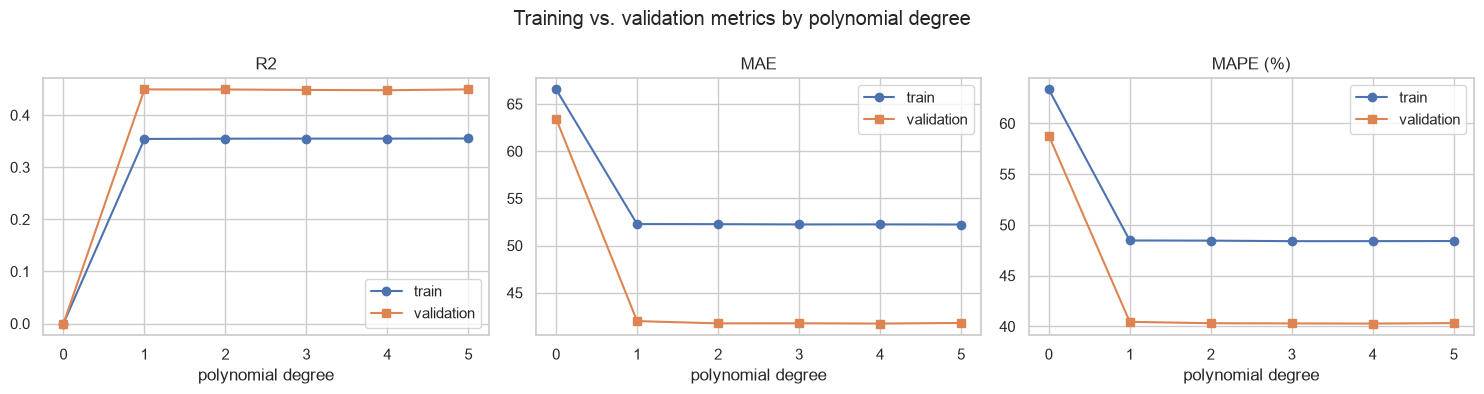

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["R2", "MAE", "MAPE (%)"]):
    ax.plot(range(6), bmi_results[f"Train {metric}"], "o-", label="train")
    ax.plot(range(6), bmi_results[f"Val {metric}"], "s-", label="validation")
    ax.set(title=metric, xlabel="polynomial degree")
    ax.legend()
fig.suptitle("Training vs. validation metrics by polynomial degree")
fig.tight_layout()
plt.show()

**Observations**
- **Degree 0 (baseline)** has R² ≈ 0 by construction – it explains no variance.
- Going from degree 0 to degree 1 is the only big improvement (validation R² jumps from 0 to
  ≈ 0.45, MAE drops by ≈ 21 points).
- Degrees 2–5 are practically **indistinguishable** from degree 1 (differences in the third
  decimal). The relationship between BMI and progression is essentially linear, and the extra
  curvature only fits noise.
- Validation scores are slightly *better* than training scores. This is not a sign of a
  problem – the validation set is small (45 patients) and happens to be a little easier; it
  does tell us validation estimates are noisy.
- MAPE is high (≈ 40–48 %) for every model, largely driven by patients with low target values
  where a small absolute error is a large percentage error.

> 📝 *Explanation to expand.*

## 8. Identify the best model

In [18]:
pd.DataFrame({
    "best model": [bmi_results["Val R2"].idxmax(), bmi_results["Val MAE"].idxmin(),
                   bmi_results["Val MAPE (%)"].idxmin()],
    "value": [bmi_results["Val R2"].max(), bmi_results["Val MAE"].min(),
              bmi_results["Val MAPE (%)"].min()],
    "degree 1 value": bmi_results.loc["Degree 1", ["Val R2", "Val MAE", "Val MAPE (%)"]].values,
}, index=["Val R2", "Val MAE", "Val MAPE (%)"]).round(3)

,best model,value,degree 1 value
Val R2,Degree 5,0.449,0.449
Val MAE,Degree 4,41.737,41.998
Val MAPE (%),Degree 4,40.276,40.445


Each metric picks a slightly different "winner", and every winner is within **0.3 points of
MAE, 0.2 % of MAPE and 0.001 of R²** of the degree-1 model – far smaller than the noise we
would expect from a 45-patient validation set.

When models perform the same, we choose the **simplest** one (Occam's razor): it has the
fewest parameters, is the least likely to overfit, extrapolates more safely to unusual BMI
values, and is the easiest for a physician to interpret.

**Chosen model: degree 1 (simple linear regression on BMI).**

In [19]:
BEST_DEGREE = 1
best_bmi_model = bmi_models[BEST_DEGREE]

## 9. Evaluate the chosen model on the test set

The test set has not been used for any decision so far, so this is our unbiased estimate of
how the model would perform on new patients.

In [20]:
bmi_test_results = pd.DataFrame({
    "train": regression_metrics(y_train, best_bmi_model.predict(X_train_bmi)),
    "validation": regression_metrics(y_val, best_bmi_model.predict(X_val_bmi)),
    "test": regression_metrics(y_test, best_bmi_model.predict(X_test_bmi)),
}).T
bmi_test_results.round(3)

,R2,MAE,MAPE (%)
train,0.354,52.278,48.462
validation,0.449,41.998,40.445
test,0.204,54.934,48.750


**Test results:** R² ≈ 0.20, MAE ≈ 55, MAPE ≈ 49 %.

- Test performance is clearly **worse than validation** (R² 0.45 → 0.20). The validation set
  (45 patients) turned out to be an optimistic sample; train and test MAE/MAPE are very close
  to each other (≈ 52–55 and ≈ 48–49 %), which suggests the training numbers are the more
  realistic expectation.
- Since a straight line cannot overfit much, the drop is due to **sampling noise in small
  splits**, not overfitting. Cross-validation would give a more stable estimate.
- An average error of ≈ 55 progression points (target std ≈ 77) means BMI alone is a weak
  predictor.

> 📝 *Explanation to expand.*

## 10. Plot the train, validation and test data with the model fit

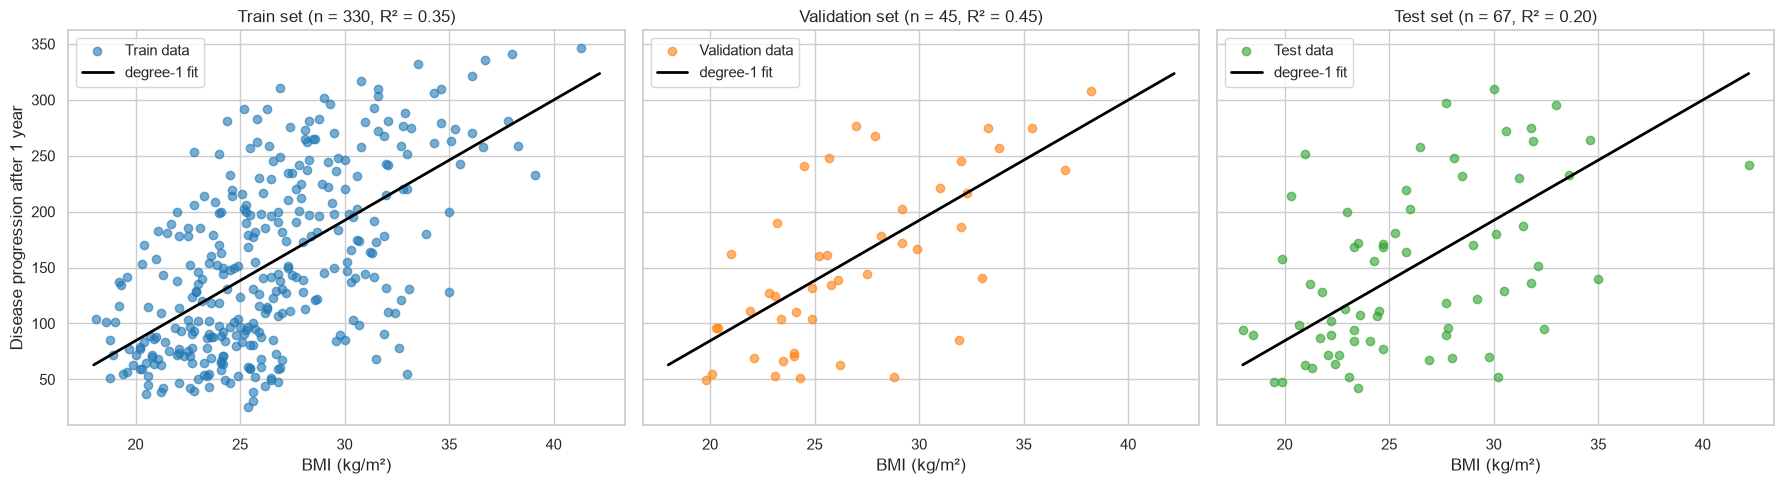

In [21]:
bmi_grid = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 200)})
bmi_fit = best_bmi_model.predict(bmi_grid)

splits = [("Train", X_train_bmi, y_train, "tab:blue"),
          ("Validation", X_val_bmi, y_val, "tab:orange"),
          ("Test", X_test_bmi, y_test, "tab:green")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, X_split, y_split, color) in zip(axes, splits):
    r2 = r2_score(y_split, best_bmi_model.predict(X_split))
    ax.scatter(X_split["bmi"], y_split, alpha=0.6, color=color, label=f"{name} data")
    ax.plot(bmi_grid["bmi"], bmi_fit, color="black", lw=2, label=f"degree-{BEST_DEGREE} fit")
    ax.set(title=f"{name} set (n = {len(y_split)}, R² = {r2:.2f})", xlabel="BMI (kg/m²)")
    ax.legend()
axes[0].set_ylabel("Disease progression after 1 year")
fig.tight_layout()
plt.show()

The line follows the upward trend in all three sets, but the points are spread widely around
it – for patients with a BMI between 24 and 26, actual progression ranges from 25 to 292.
The test set also contains the most extreme BMI (≈ 42), where the line over-predicts.

> 📝 *Explanation to expand.*

## 11. Equation of the best model

In [22]:
feature_names = best_bmi_model.named_steps["poly"].get_feature_names_out()
coefs = best_bmi_model.named_steps["linreg"].coef_

terms = []
for name, coef in zip(feature_names, coefs):
    terms.append(f"{coef:.2f}" if name == "1" else f"{coef:.2f}·{name}")
equation = "progression = " + " + ".join(terms).replace("+ -", "- ")
print(equation)

progression = -130.87 + 10.77·bmi


$$\widehat{\text{progression}} = -130.87 + 10.77 \times \text{BMI}$$

- **Slope:** each additional 1 kg/m² of BMI is associated with ≈ 10.8 more points of disease
  progression after one year.
- **Intercept:** −130.87 is the value at BMI = 0, which is physically impossible – it only
  anchors the line and should not be interpreted on its own. Within the observed range
  (BMI 18–42) predictions are 63–323.

> 📝 *Explanation to expand.*

## 12. Predict progression for a chosen BMI value

We use BMI = 30 kg/m², the clinical threshold for obesity.

In [23]:
bmi_value = pd.DataFrame({"bmi": [30.0]})
predicted = best_bmi_model.predict(bmi_value)[0]
print(f"Predicted progression for BMI = {bmi_value['bmi'][0]}: {predicted:.2f}")
print(f"Check with the equation: {coefs[0] + coefs[1] * 30:.2f}")

Predicted progression for BMI = 30.0: 192.17
Check with the equation: 192.17


A patient with BMI 30 is predicted to score ≈ 192 – above the dataset median (≈ 140), so
they would lean towards the higher-risk group. Given a test MAE of ≈ 55, the true value could
easily be anywhere from ≈ 137 to ≈ 247.

> 📝 *Explanation to expand.*

## 13. Number of trainable parameters per model

In [24]:
param_table = pd.DataFrame([
    {
        "model": f"Degree {degree}",
        "features (get_feature_names_out)": ", ".join(model.named_steps["poly"].get_feature_names_out()),
        "trainable parameters": model.named_steps["linreg"].coef_.size,
    }
    for degree, model in bmi_models.items()
]).set_index("model")
param_table

,features (get_feature_names_out),trainable parameters
model,,
Degree 0,1,1
Degree 1,"1, bmi",2
Degree 2,"1, bmi, bmi^2",3
Degree 3,"1, bmi, bmi^2, bmi^3",4
Degree 4,"1, bmi, bmi^2, bmi^3, bmi^4",5
Degree 5,"1, bmi, bmi^2, bmi^3, bmi^4, bmi^5",6


A degree-*d* univariate polynomial $\hat y = w_0 + w_1x + w_2x^2 + \dots + w_dx^d$ has
**d + 1 trainable parameters**: one weight per power of BMI from $x^0$ (the bias column `1`,
i.e. the intercept) up to $x^d$. So the six models have 1, 2, 3, 4, 5 and 6 parameters.

- Degree 0 learns only the intercept (= the training mean).
- Our chosen degree-1 model learns 2: intercept −130.87 and slope 10.77.
- Extra parameters in degrees 2–5 bought no validation improvement – more flexibility, no gain.

## 14. Conclusions – Part 2
### 14.1 Where does the model fail?

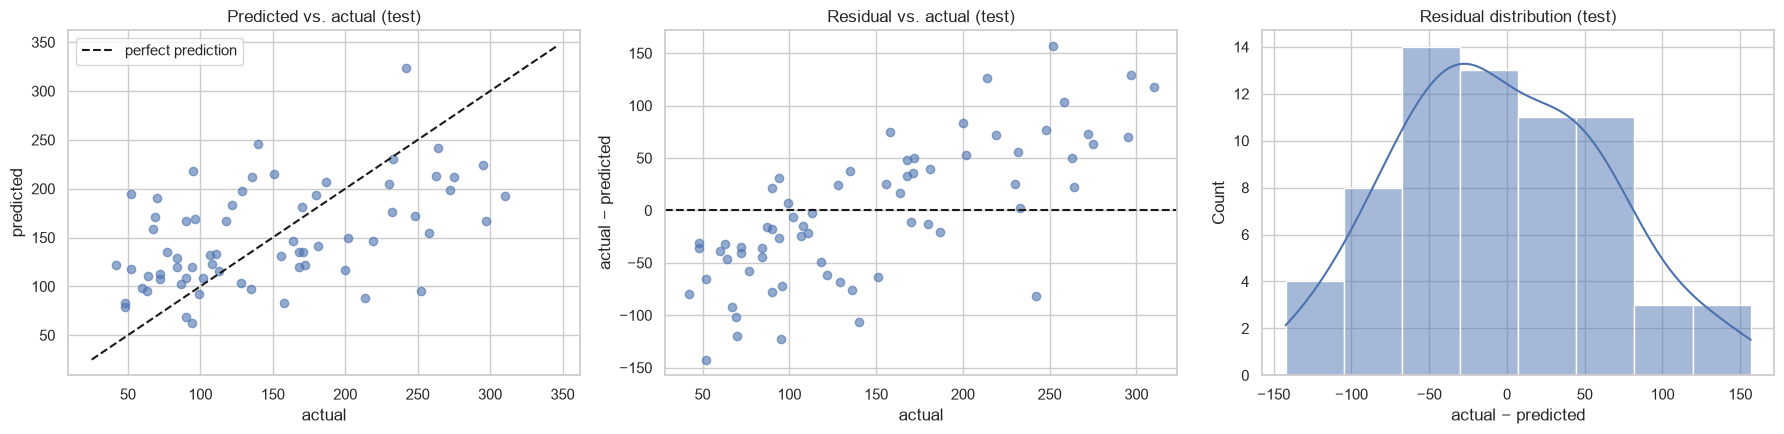

In [25]:
test_pred = best_bmi_model.predict(X_test_bmi)
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].scatter(y_test, test_pred, alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", label="perfect prediction")
axes[0].set(title="Predicted vs. actual (test)", xlabel="actual", ylabel="predicted")
axes[0].legend()
axes[1].scatter(y_test, residuals, alpha=0.6)
axes[1].axhline(0, color="k", ls="--")
axes[1].set(title="Residual vs. actual (test)", xlabel="actual", ylabel="actual − predicted")
sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set(title="Residual distribution (test)", xlabel="actual − predicted")
fig.tight_layout()
plt.show()

In [26]:
target_band = pd.qcut(y_test, 3, labels=["low", "medium", "high"])
pd.DataFrame({"actual": y_test, "predicted": test_pred, "abs error": residuals.abs(),
              "APE (%)": 100 * residuals.abs() / y_test, "band": target_band}) \
    .groupby("band", observed=True).agg(n=("actual", "size"), mean_actual=("actual", "mean"),
                                        mean_predicted=("predicted", "mean"),
                                        MAE=("abs error", "mean"), MAPE=("APE (%)", "mean")).round(1)

,n,mean_actual,mean_predicted,MAE,MAPE
band,,,,,
low,23,72.3,124.8,57.1,86.4
medium,22,134.1,146.7,40.1,30.2
high,22,237.5,180.5,67.5,27.9


**Screening view.** If we flag a patient as *high risk* when the predicted progression is above
the training median, how often do we catch the patients who really are above it?

In [27]:
from sklearn.metrics import confusion_matrix, classification_report

RISK_THRESHOLD = y_train.median()
actual_high = (y_test > RISK_THRESHOLD).astype(int)
flagged_high = (test_pred > RISK_THRESHOLD).astype(int)

print(f"Risk threshold (training median): {RISK_THRESHOLD}")
print(pd.DataFrame(confusion_matrix(actual_high, flagged_high),
                   index=["actual low", "actual high"], columns=["flagged low", "flagged high"]))
print(classification_report(actual_high, flagged_high, target_names=["low", "high"]))

Risk threshold (training median): 142.0
             flagged low  flagged high
actual low            25            12
actual high           10            20
              precision    recall  f1-score   support

         low       0.71      0.68      0.69        37
        high       0.62      0.67      0.65        30

    accuracy                           0.67        67
   macro avg       0.67      0.67      0.67        67
weighted avg       0.67      0.67      0.67        67



**Failure analysis**
- **Regression to the mean:** the model squeezes all predictions towards the centre. For the
  lowest-progression third of test patients it over-predicts by ≈ 52 points on average
  (MAPE ≈ 86 %), and for the highest third it under-predicts by ≈ 57 points.
- **Largest absolute errors are in the high-progression group** (MAE ≈ 68) – exactly the
  patients a screening tool most needs to identify.
- **MAPE is inflated by low-target patients:** a 50-point error on a patient whose true value
  is 40 counts as 125 %, so MAPE mostly reflects the low band.
- **Extreme BMI values** (e.g. the test patient at BMI ≈ 42) are extrapolations from very few
  training examples.
- **As a screening tool** (threshold = training median), the model catches only **67 % of
  truly high-progression patients (recall)** – 10 of 30 at-risk patients would be missed (false
  negatives) – and 38 % of flagged patients are false alarms (precision 0.62). Overall accuracy
  is 67 %.

### 14.2 Summary
- BMI is the single strongest predictor, and the relationship is essentially **linear** – a
  degree-1 model performs as well as degrees 2–5 with fewer parameters.
- Chosen model: $\widehat{\text{progression}} = -130.87 + 10.77 \times \text{BMI}$.
- Test performance: **R² ≈ 0.20, MAE ≈ 55, MAPE ≈ 49 %** – better than the mean baseline, but
  BMI alone explains only a small part of the variation in progression.

### 14.3 Limitations
- **One feature cannot capture a multi-factor disease.** Blood pressure, triglycerides (`ltg`)
  and HDL also correlate with progression and are ignored here → Part 3.
- **Small data, noisy estimates:** with 45 validation and 67 test patients, metrics shift a lot
  between splits (validation R² 0.45 vs test 0.20). k-fold cross-validation would be more reliable.
- **Correlation, not causation:** the slope describes an association in this cohort; it does not
  say that lowering BMI by one unit lowers progression by 10.8.
- **Raw high-degree polynomials are numerically unstable** (BMI⁵ ≈ 10⁸), which is why their
  coefficients look odd – another reason to prefer the low-degree model.
- **Generalisability:** 442 patients from a single study; performance on other populations is unknown.

### 14.4 Talking points from the workshops
- *Performance metrics:* R²/MAE describe average accuracy, but for screening what matters is the
  **confusion matrix** – especially **recall** of high-risk patients. Lowering the risk threshold
  would catch more at-risk patients at the cost of more false alarms, which is usually acceptable
  when follow-up tests are cheap.
- *Logistic regression:* framing the task directly as high vs. low risk lets the model output a
  **probability of high progression**, so the threshold can be tuned for recall.
- *kNN:* a non-parametric model that uses several (scaled) features could pick up patterns a
  single straight line misses – but needs care with *k* and feature scaling.

> 📝 *Explanation to expand.*